In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rating=pd.read_csv("Data/ratings.csv")
movie=pd.read_csv("Data/movies.csv")
print(rating)
print(movie)


        userId  movieId  rating   timestamp
0            1        1     4.0   964982703
1            1        3     4.0   964981247
2            1        6     4.0   964982224
3            1       47     5.0   964983815
4            1       50     5.0   964982931
...        ...      ...     ...         ...
100831     610   166534     4.0  1493848402
100832     610   168248     5.0  1493850091
100833     610   168250     5.0  1494273047
100834     610   168252     5.0  1493846352
100835     610   170875     3.0  1493846415

[100836 rows x 4 columns]
      movieId                                      title  \
0           1                           Toy Story (1995)   
1           2                             Jumanji (1995)   
2           3                    Grumpier Old Men (1995)   
3           4                   Waiting to Exhale (1995)   
4           5         Father of the Bride Part II (1995)   
...       ...                                        ...   
9737   193581  Black Butl

In [2]:
#database statistics
nusers=rating.userId.nunique()
nmovies=rating.movieId.nunique()  # only movies that have at least one rating
nrating=len(rating.rating)
Sparsity=(1-(nrating/(nusers*nmovies)))*100
print(nusers,nmovies,nrating,Sparsity)

610 9724 100836 98.30003169443864


In [3]:
#Make a User-Item Matrix
rating_matrix = rating.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

rating_matrix

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,2.5,NaN,NaN,NaN,NaN,NaN,2.5,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
607,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
608,2.5,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
#rating ditribution
rating_dist=rating.rating.value_counts()
print(rating_dist)
#rating per user
user_dis=rating.userId.value_counts()
print(user_dis)

rating
4.0    26818
3.0    20047
5.0    13211
3.5    13136
4.5     8551
2.0     7551
2.5     5550
1.0     2811
1.5     1791
0.5     1370
Name: count, dtype: int64
userId
414    2698
599    2478
474    2108
448    1864
274    1346
       ... 
431      20
442      20
569      20
576      20
595      20
Name: count, Length: 610, dtype: int64


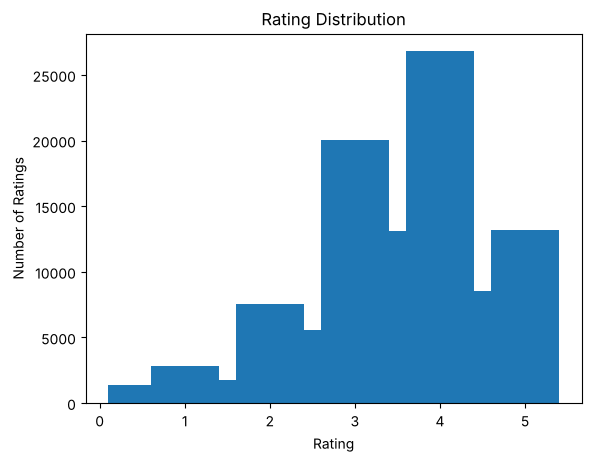

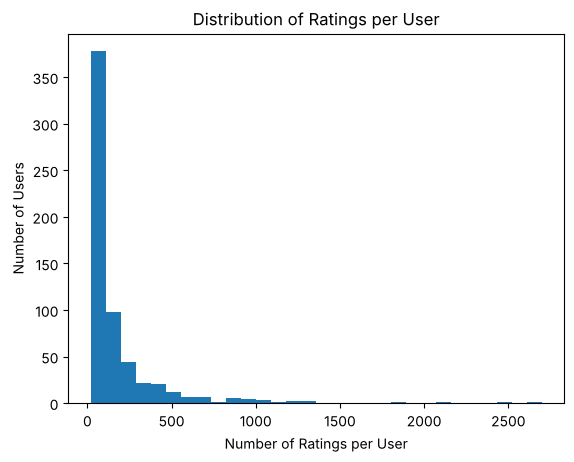

In [5]:
#bar_chart per rating (get some help from ai)
plt.bar(rating_dist.index, rating_dist.values)
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Rating Distribution")
plt.show()
#bar_chart per user
plt.hist(user_dis.values, bins=30)
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")
plt.title("Distribution of Ratings per User")
plt.show()

In [6]:
def get_co_rated(matrix, a, b, axis):
    # a and b are real IDs (userId or movieId), not positions
    if axis == "index":
        first = matrix.loc[a]
        second = matrix.loc[b]
    elif axis == "columns":
        first = matrix.loc[:, a]
        second = matrix.loc[:, b]
    else:
        raise ValueError('axis must be "index" or "columns"')

    # keep only the entries where both have a rating
    mask = ~np.isnan(first) & ~np.isnan(second)
    return first[mask].values, second[mask].values


In [7]:
# Euclidean similarity
def euclidean_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    d = np.sqrt(np.sum((vec1 - vec2)**2))
    similarity = 1/(1+d)
    return similarity

# Cosine similarity
def cosine_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    denominator = np.linalg.norm(vec1) * np.linalg.norm(vec2) # ai help with linalg.norm

    if denominator == 0:
        return None

    similarity = np.dot(vec1, vec2) / denominator

    return similarity

# Pearson similarity
def pearson_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    # Pearson is the cosine similarity of the mean-centered vectors
    vec1_centered = vec1 - np.mean(vec1)
    vec2_centered = vec2 - np.mean(vec2)
    return cosine_similarity(vec1_centered, vec2_centered)


In [8]:
# sanity check against the worked example in Section 3.2
A = np.array([5, 4, 5, 3])
B = np.array([3, 2, 3, 1])
print("Euclidean distance:  ", np.sqrt(np.sum((A - B)**2)))              # 4.0
print("Euclidean similarity:", euclidean_similarity(A, B))               # 0.2 (= 1/(1+4))
print("Cosine:              ", round(cosine_similarity(A, B), 3))        # 0.987
print("Pearson:             ", round(pearson_similarity(A, B), 3))       # 1.0


Euclidean distance:   4.0
Euclidean similarity: 0.2
Cosine:               0.987
Pearson:              1.0


In [9]:
# get_co_rated on a toy matrix whose ids are NOT 0,1,2... (like MovieLens)
toy = pd.DataFrame([[5, 4, 5, 3], [3, 2, 3, 1]], index=[10, 20], columns=[101, 102, 103, 104])
v1, v2 = get_co_rated(toy, 10, 20, "index")
print(v1, v2)                                             # [5 4 5 3] [3 2 3 1]

# get_co_rated on the real matrix: users 1 and 2 share 2 movies, users 1 and 5 share 13
v1, v2 = get_co_rated(rating_matrix, 1, 2, "index")
print(len(v1), v1, v2)
v1, v2 = get_co_rated(rating_matrix, 1, 5, "index")
print(len(v1))

# the three metrics on a real pair of users (fewer than 2 co-rated entries gives None)
print(euclidean_similarity(v1, v2), cosine_similarity(v1, v2), pearson_similarity(v1, v2))


[5 4 5 3] [3 2 3 1]
2 [5. 5.] [4. 4.]
13
0.21089672205953397 0.9707699301444195 0.26874902634577136


In [10]:
def find_k_nearest_users(matrix, target_user, k, similarity_fn):
    scores = []
    for other_user in matrix.index:
        if other_user == target_user:
            continue  # a user is not their own neighbor

        vec1, vec2 = get_co_rated(matrix, target_user, other_user, axis="index")
        if len(vec1) < 2:
            continue  # fewer than 2 co-rated items: similarity is undefined, skip

        score = similarity_fn(vec1, vec2)
        if score is None:
            continue  # the metric could not be computed for this pair

        scores.append((other_user, score))

    scores.sort(key=lambda pair: pair[1], reverse=True)
    return scores[:k]


In [11]:
# the 5 nearest users to user 1 with each similarity metric: (user id, score)
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    nearest = find_k_nearest_users(rating_matrix, 1, 5, fn)
    print(name, [(int(user), round(float(score), 3)) for user, score in nearest])


euclidean [(77, 1.0), (278, 0.667), (472, 0.667), (511, 0.667), (550, 0.667)]


cosine [(77, 1.0), (12, 1.0), (2, 1.0), (511, 0.999), (278, 0.999)]


pearson [(146, 1.0), (106, 1.0), (333, 1.0), (550, 1.0), (598, 1.0)]


In [12]:
def predict_rating_user_based(matrix, target_user, target_item, k, similarity_fn):
    if target_user not in matrix.index or target_item not in matrix.columns:
        return None  # unknown user or item: nothing to predict from

    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)

    numerator = 0.0
    denominator = 0.0
    for neighbor, similarity in neighbors:
        neighbor_rating = matrix.loc[neighbor, target_item]
        if np.isnan(neighbor_rating):
            continue  # this neighbor did not rate the target item
        numerator += similarity * neighbor_rating
        denominator += abs(similarity)

    if denominator == 0:
        return None  # none of the k neighbors rated the item
    return numerator / denominator


In [13]:
# predicted rating of user 1 for movie 318 with k=20 and each similarity metric
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    print(name, predict_rating_user_based(rating_matrix, 1, 318, 20, fn))


euclidean 4.7918967920028095


cosine 4.449845252882381


pearson 4.623973837700031
